In [1]:
import os
import random
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

DATA_DIR = './data'
IMAGE_SIZE = 32
K_VALUES = [1, 3, 5, 7, 9, 11, 15]
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

name_folders = sorted(
    d for d in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, d))
)
print(f'Классов: {len(name_folders)}')
print(name_folders)

# папка times на выводе показывается как *
DISPLAY = {name: ('*' if name == 'times' else name) for name in name_folders}


Классов: 21
['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'X', 'h', 't', 'times', 'w', 'y']


# 1. Загрузка датасета и преобразование изображения в вектор


In [2]:
def to_vector(img_inv, size=IMAGE_SIZE):
    # обрезка по ненулевым пикселям, дополнение до квадрата, resize 32x32
    ys, xs = np.where(img_inv > 50)
    if len(xs) > 0:
        img_inv = img_inv[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = img_inv.shape
    side = max(h, w)
    square = np.zeros((side, side), np.uint8)
    square[(side - h) // 2:(side - h) // 2 + h,
           (side - w) // 2:(side - w) // 2 + w] = img_inv
    square = cv.resize(square, (size, size), interpolation=cv.INTER_AREA)
    return square.astype(np.float32).ravel() / 255.0


def load_dataset():
    X, y = [], []
    class_files = {}
    for idx, cls in enumerate(name_folders):
        folder = os.path.join(DATA_DIR, cls)
        # только картинки верхнего уровня: в data/8 есть вложенная папка 1,
        # из-за нее os.walk дает 22 класса с дублем 1
        files = sorted(
            f for f in os.listdir(folder)
            if os.path.isfile(os.path.join(folder, f))
            and f.lower().endswith(('.jpg', '.jpeg', '.png'))
        )
        class_files[cls] = [os.path.join(folder, f) for f in files]
        for f in files:
            img = cv.imread(os.path.join(folder, f), cv.IMREAD_GRAYSCALE)
            if img is None:
                continue
            img = cv.bitwise_not(img)
            X.append(to_vector(img))
            y.append(idx)
    return np.array(X, dtype=np.float32), np.array(y), class_files


X, y, class_files = load_dataset()
print('X:', X.shape, ' y:', y.shape)
for idx, cls in enumerate(name_folders):
    print(f'{DISPLAY[cls]:>3}: {(y == idx).sum()}')


X: (225291, 1024)  y: (225291,)
  (: 14294
  ): 14355
  +: 25112
  ,: 1906
  -: 33997
  0: 6914
  1: 26520
  2: 26141
  3: 10909
  4: 7396
  5: 3545
  6: 3118
  7: 2909
  8: 3068
  9: 628
  X: 26594
  h: 1464
  t: 3274
  *: 3251
  w: 556
  y: 9340


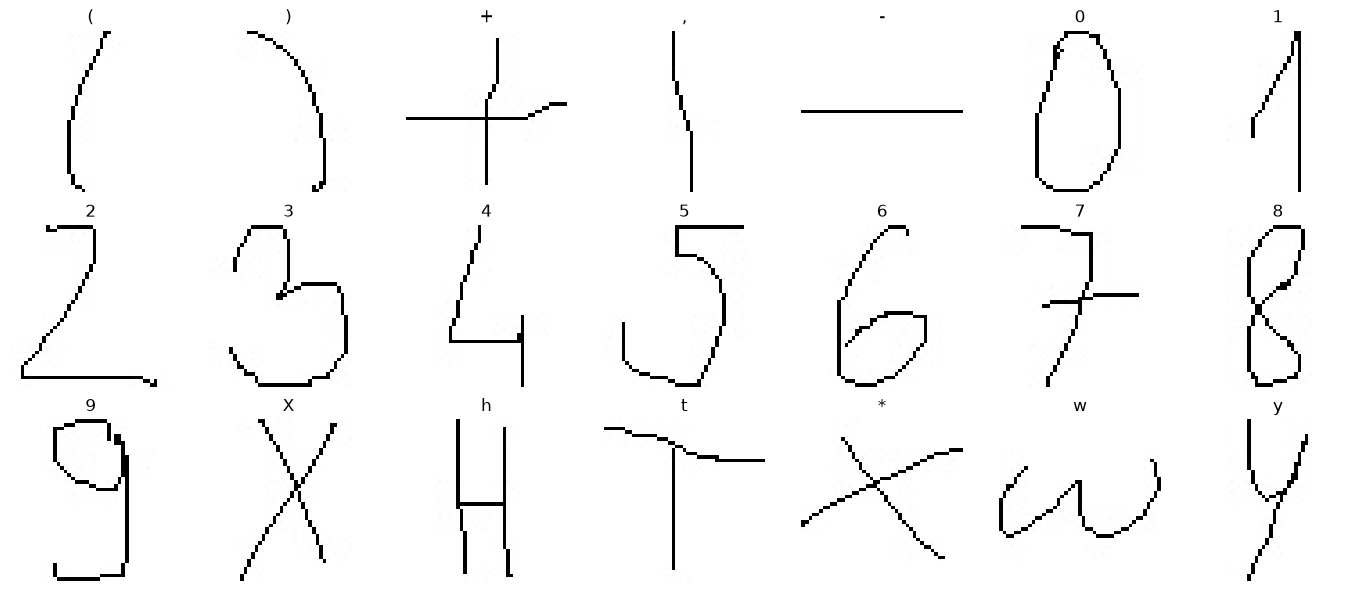

In [3]:
# примеры символов по классам
fig, axes = plt.subplots(3, 7, figsize=(14, 6))
for ax, cls in zip(axes.ravel(), name_folders):
    img = cv.imread(class_files[cls][0], cv.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap='gray')
    ax.set_title(DISPLAY[cls])
    ax.axis('off')
plt.tight_layout()
plt.show()


# 2. Классификация символов методом k-NN, подбор k по accuracy


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)
del X, y

# подвыборка теста для быстрого подбора k
rng = np.random.default_rng(RANDOM_STATE)
val_idx = rng.choice(len(X_test), size=min(3000, len(X_test)), replace=False)
X_val, y_val = X_test[val_idx], y_test[val_idx]
print('Validation (для подбора k):', X_val.shape)


Train: (180232, 1024)  Test: (45059, 1024)
Validation (для подбора k): (3000, 1024)


k =  1 | accuracy (val) = 0.9910


k =  3 | accuracy (val) = 0.9567


k =  5 | accuracy (val) = 0.8770


k =  7 | accuracy (val) = 0.8540


k =  9 | accuracy (val) = 0.8430


k = 11 | accuracy (val) = 0.8237


k = 15 | accuracy (val) = 0.7843

Оптимальное k = 1, accuracy = 0.9910


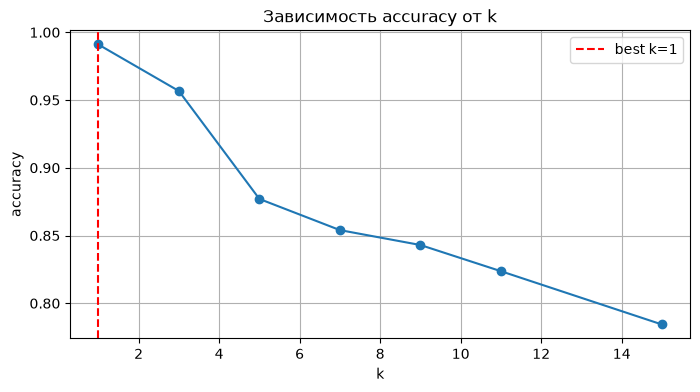

In [5]:
accuracies = []
for k in K_VALUES:
    clf = KNeighborsClassifier(n_neighbors=k, n_jobs=-1, algorithm='brute')
    clf.fit(X_train, y_train)
    acc = accuracy_score(y_val, clf.predict(X_val))
    accuracies.append(acc)
    print(f'k = {k:2d} | accuracy (val) = {acc:.4f}')

best_k = K_VALUES[int(np.argmax(accuracies))]
print(f'\nОптимальное k = {best_k}, accuracy = {max(accuracies):.4f}')

plt.figure(figsize=(8, 4))
plt.plot(K_VALUES, accuracies, marker='o')
plt.axvline(best_k, color='r', ls='--', label=f'best k={best_k}')
plt.xlabel('k')
plt.ylabel('accuracy')
plt.grid(True)
plt.legend()
plt.title('Зависимость accuracy от k')
plt.show()


Test accuracy (k=1): 0.9931

              precision    recall  f1-score   support

           (       0.99      1.00      0.99      2859
           )       0.99      1.00      0.99      2871
           +       1.00      0.99      0.99      5022
           ,       0.95      0.93      0.94       381
           -       0.99      1.00      1.00      6799
           0       1.00      1.00      1.00      1383
           1       0.99      1.00      0.99      5304
           2       0.99      1.00      0.99      5228
           3       0.99      0.99      0.99      2182
           4       1.00      0.99      1.00      1479
           5       1.00      0.99      0.99       709
           6       1.00      0.97      0.98       624
           7       1.00      0.99      0.99       582
           8       1.00      0.96      0.98       614
           9       1.00      0.50      0.67       126
           X       1.00      0.99      1.00      5319
           h       1.00      1.00      1.00       29

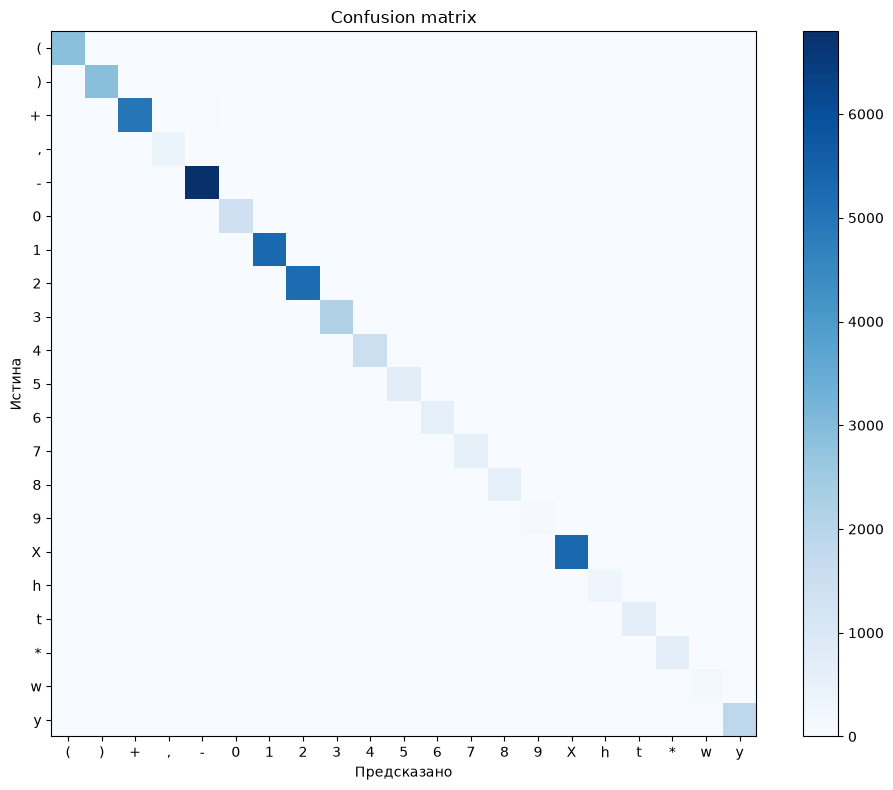

In [6]:
# финальная модель с лучшим k, отчет на полном тесте
best_knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1, algorithm='brute')
best_knn.fit(X_train, y_train)
y_pred = best_knn.predict(X_test)
print(f'Test accuracy (k={best_k}): {accuracy_score(y_test, y_pred):.4f}\n')
print(classification_report(
    y_test, y_pred,
    target_names=[DISPLAY[c] for c in name_folders], zero_division=0))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks(range(len(name_folders)), [DISPLAY[c] for c in name_folders])
plt.yticks(range(len(name_folders)), [DISPLAY[c] for c in name_folders])
plt.xlabel('Предсказано')
plt.ylabel('Истина')
plt.title('Confusion matrix')
plt.tight_layout()
plt.show()


# 3. Генератор последовательностей символов


(3 2-, *8  |  0+3
t1  |  (w+7)*4
853  |  (3-1)
,66w3  |  7*1
t4 *1+)  |  (4+3)


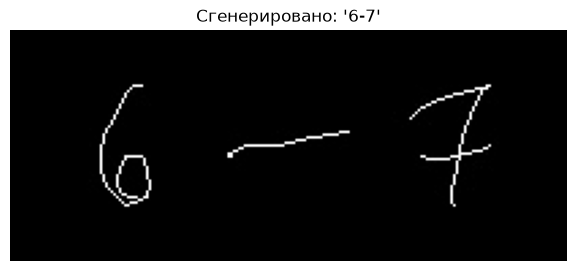

In [7]:
def generate_text(num_words=None, min_len=2, max_len=5):
    if num_words is None:
        num_words = random.randint(1, 3)
    words = []
    for _ in range(num_words):
        length = random.randint(min_len, max_len)
        word = ''.join(DISPLAY[random.choice(name_folders)] for _ in range(length))
        words.append(word)
    return ' '.join(words)


def generate_expression():
    d = lambda: random.choice('0123456789')
    v = lambda: random.choice('Xhtwy')
    op = lambda: random.choice('+-*')
    tpl = random.choice([
        lambda: f'{d()}{op()}{d()}',
        lambda: f'({d()}{op()}{d()})',
        lambda: f'{v()}{op()}{d()}',
        lambda: f'{v()}({d()}{op()}{d()})',
        lambda: f'({v()}{op()}{d()}){op()}{d()}',
    ])
    return tpl()


def text_to_images(text):
    images = []
    for ch in text:
        if ch == ' ':
            images.append(None)
            continue
        folder = 'times' if ch == '*' else ch
        path = random.choice(class_files[folder])
        img = cv.imread(path, cv.IMREAD_GRAYSCALE)
        images.append(cv.bitwise_not(img))
    return images


def render_sequence(text, char_gap=15, space_width=45, margin=20):
    parts = []
    for img in text_to_images(text):
        if img is None:
            parts.append(np.zeros((45, space_width), np.uint8))
        else:
            parts.append(img)
            parts.append(np.zeros((img.shape[0], char_gap), np.uint8))
    if parts:
        parts.pop()
    strip = np.hstack(parts)
    canvas = np.zeros((strip.shape[0] + 2 * margin, strip.shape[1] + 2 * margin), np.uint8)
    canvas[margin:margin + strip.shape[0], margin:margin + strip.shape[1]] = strip
    return canvas


for _ in range(5):
    print(generate_text(), ' | ', generate_expression())

demo_text = generate_expression()
demo_img = render_sequence(demo_text)
plt.figure(figsize=(10, 3))
plt.imshow(demo_img, cmap='gray')
plt.title(f'Сгенерировано: {demo_text!r}')
plt.axis('off')
plt.show()


# 4. Распознавание последовательности символов


In [8]:
def segment_symbols(img_inv, min_area=30, merge_gap=10):
    # выделение объектов как в inf_net: порог, контуры, boundingRect, сортировка по x
    # min_area=30 и без фильтра по высоте, иначе теряются - и ,
    _, thresh = cv.threshold(img_inv, 127, 255, cv.THRESH_BINARY)
    kernel = np.ones((3, 1), np.uint8)
    thresh = cv.morphologyEx(thresh, cv.MORPH_CLOSE, kernel)
    contours, _ = cv.findContours(thresh, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    boxes = [cv.boundingRect(c) for c in contours]
    boxes = [b for b in boxes if b[2] * b[3] > min_area]
    boxes.sort(key=lambda b: b[0])

    merged = []
    for x, y, w, h in boxes:
        if merged and x <= merged[-1][0] + merged[-1][2] + merge_gap:
            px, py, pw, ph = merged[-1]
            nx, ny = min(px, x), min(py, y)
            merged[-1] = [nx, ny, max(px + pw, x + w) - nx, max(py + ph, y + h) - ny]
        else:
            merged.append([x, y, w, h])
    return [tuple(b) for b in merged]


def recognize_sequence(img_inv, model):
    boxes = segment_symbols(img_inv)
    if not boxes:
        return '', boxes
    # пробел по расстоянию между центрами символов
    centers = [x + w / 2 for x, y, w, h in boxes]
    dists = [centers[i + 1] - centers[i] for i in range(len(centers) - 1)]
    med = np.median(dists) if dists else 0
    out = []
    for i, (x, y, w, h) in enumerate(boxes):
        if i > 0 and (centers[i] - centers[i - 1]) > max(82, 1.4 * med):
            out.append(' ')
        crop = img_inv[max(0, y - 3):y + h + 3, max(0, x - 3):x + w + 3]
        vec = to_vector(crop).reshape(1, -1)
        pred = int(model.predict(vec)[0])
        out.append(DISPLAY[name_folders[pred]])
    return ''.join(out), boxes


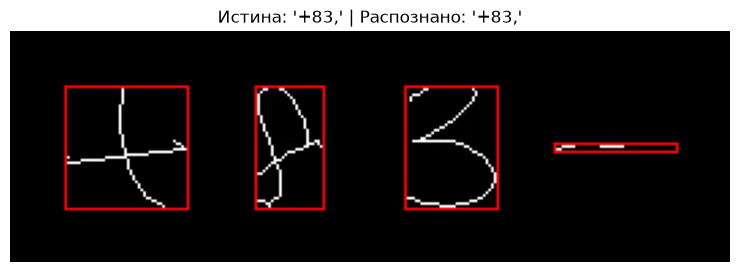

True: '+83,'                    Pred: '+83,'                    char_acc=1.00


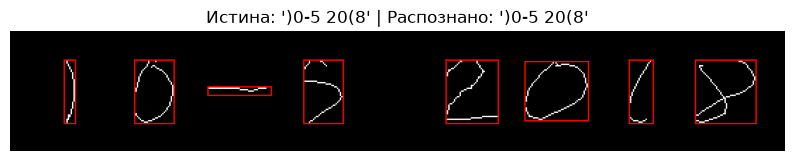

True: ')0-5 20(8'               Pred: ')0-5 20(8'               char_acc=1.00


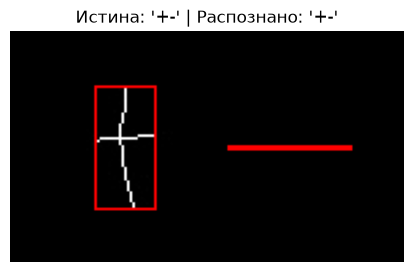

True: '+-'                      Pred: '+-'                      char_acc=1.00


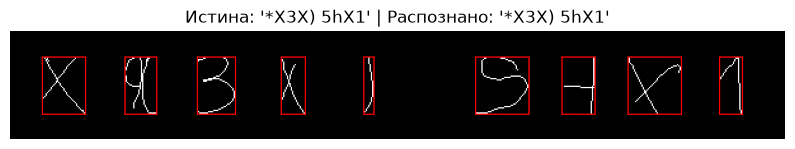

True: '*X3X) 5hX1'              Pred: '*X3X) 5hX1'              char_acc=1.00


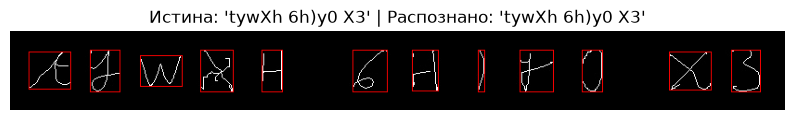

True: 'tywXh 6h)y0 X3'          Pred: 'tywXh 6h)y0 X3'          char_acc=1.00


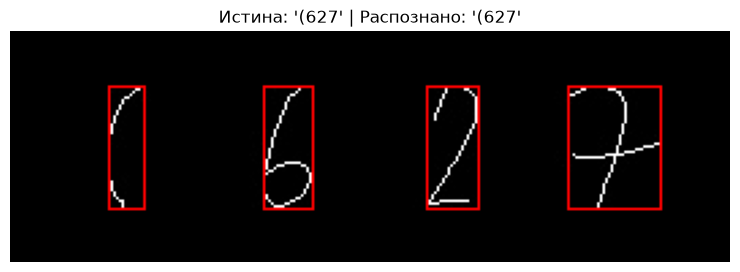

True: '(627'                    Pred: '(627'                    char_acc=1.00


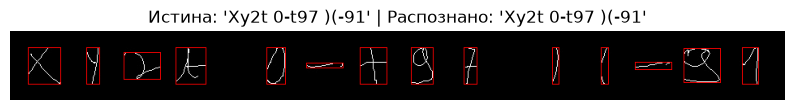

True: 'Xy2t 0-t97 )(-91'        Pred: 'Xy2t 0-t97 )(-91'        char_acc=1.00


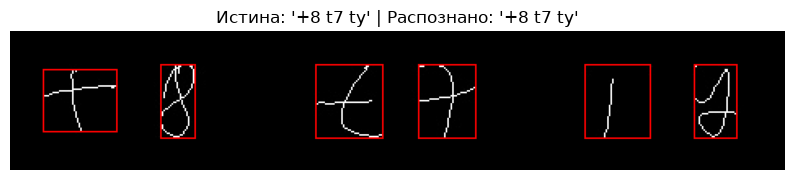

True: '+8 t7 ty'                Pred: '+8 t7 ty'                char_acc=1.00


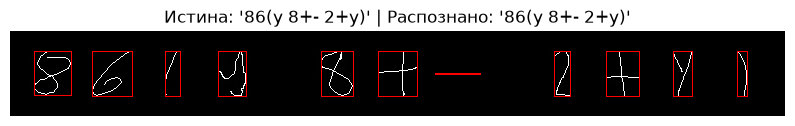

True: '86(y 8+- 2+y)'           Pred: '86(y 8+- 2+y)'           char_acc=1.00


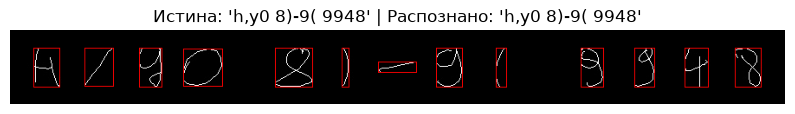

True: 'h,y0 8)-9( 9948'         Pred: 'h,y0 8)-9( 9948'         char_acc=1.00

Средняя посимвольная точность: 1.000
Точное совпадение строк: 10/10


In [9]:
def char_accuracy(true_text, pred_text):
    a = true_text.replace(' ', '')
    b = pred_text.replace(' ', '')
    n = min(len(a), len(b))
    if n == 0:
        return 0.0
    return sum(1 for x, z in zip(a, b) if x == z) / max(len(a), len(b))


random.seed(123)
scores, exact = [], 0
N = 10
for _ in range(N):
    true_text = generate_text()
    img = render_sequence(true_text)
    pred_text, boxes = recognize_sequence(img, best_knn)
    acc = char_accuracy(true_text, pred_text)
    scores.append(acc)
    exact += int(true_text == pred_text)

    vis = cv.cvtColor(img, cv.COLOR_GRAY2RGB)
    for x, y, w, h in boxes:
        cv.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 1)
    plt.figure(figsize=(10, 3))
    plt.imshow(vis)
    plt.axis('off')
    plt.title(f'Истина: {true_text!r} | Распознано: {pred_text!r}')
    plt.show()
    print(f'True: {true_text!r:25} Pred: {pred_text!r:25} char_acc={acc:.2f}')

print(f'\nСредняя посимвольная точность: {np.mean(scores):.3f}')
print(f'Точное совпадение строк: {exact}/{N}')


# 5. Проверка на test13.png


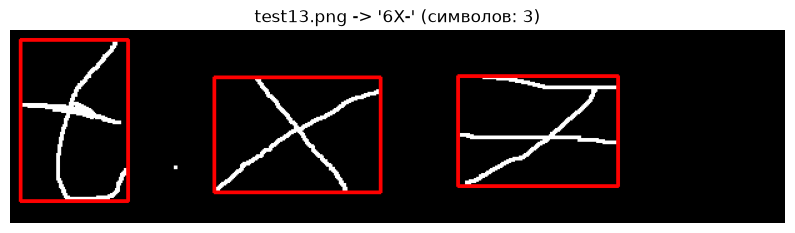

Распознано: '6X-'
Ожидается: t*7 (так распознавал MLP в inf_net)


'6X-'

In [10]:
def recognize_test_image(path='./test13.png'):
    img = cv.imread(path)
    if img is None:
        print(f'Файл {path} не найден')
        return None
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    kernel = np.ones((3, 3), np.uint8)
    img_gray = cv.erode(img_gray, kernel, iterations=1)
    img_gray = cv.bitwise_not(img_gray)
    base = np.zeros((img_gray.shape[0] + 6, img_gray.shape[1] + 6), np.uint8)
    base[3:img_gray.shape[0] + 3, 3:img_gray.shape[1] + 3] = img_gray

    text, boxes = recognize_sequence(base, best_knn)
    vis = cv.cvtColor(base, cv.COLOR_GRAY2RGB)
    for x, y, w, h in boxes:
        cv.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 2)
    plt.figure(figsize=(10, 3))
    plt.imshow(vis)
    plt.axis('off')
    plt.title(f'test13.png -> {text!r} (символов: {len(boxes)})')
    plt.show()
    print(f'Распознано: {text!r}')
    print('Ожидается: t*7 (так распознавал MLP в inf_net)')
    return text


recognize_test_image()
